%load_ext autotime

# Topic 1

## 

__Tom Kelsey__

**Chapter 10 – Introduction to Artificial Neural Networks with Keras**

_This notebook contains all the sample code and solutions to the exercises in chapter 10._

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

# Setup

This project requires Python 3.7 or above:

In [1]:
import sys

assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [2]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

And TensorFlow ≥ 2.8:

In [3]:
import tensorflow as tf

assert version.parse(tf.__version__) >= version.parse("2.8.0")

As we did in previous chapters, let's define the default font sizes to make the figures prettier:

In [4]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

And let's create the `images/ann` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the book:

In [5]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "ann"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Neural Networks

- The standard architecture is the **Multi-Layer Perceptron (MLP)**
- More complex architectures exist
    - We'll see some examples later in the module

- The **input layer** where our $x$ instances are supplied
- Possible **bias nodes** that act in the same way as the intercept terms in a linear regression model
- A number of **hidden layers**
    - Each consisting of a number of nodes
- An **output layer** where the inputs are scaled and organised into our $\hat{y}$ predictions 

<img src="images/mlp.png">

__[Source](https://medium.com/codex/introduction-to-how-an-multilayer-perceptron-works-but-without-complicated-math-a423979897ac)__

- Weights, activation functions, response scaling

# From Biological to Artificial Neurons
## The Perceptron

In [6]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0)  # Iris setosa

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)  # predicts True and False for these 2 flowers

In [7]:
y_pred

array([ True, False])

The `Perceptron` is equivalent to a `SGDClassifier` with `loss="perceptron"`, no regularization, and a constant learning rate equal to 1:

In [8]:
# extra code – shows how to build and train a Perceptron

from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(loss="perceptron", penalty=None,
                        learning_rate="constant", eta0=1, random_state=42)
sgd_clf.fit(X, y)
assert (sgd_clf.coef_ == per_clf.coef_).all()
assert (sgd_clf.intercept_ == per_clf.intercept_).all()

When the Perceptron finds a decision boundary that properly separates the classes, it stops learning. This means that the decision boundary is often quite close to one class:

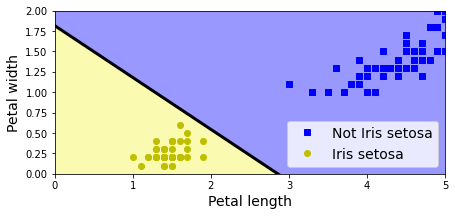

In [9]:
# extra code – plots the decision boundary of a Perceptron on the iris dataset

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

a = -per_clf.coef_[0, 0] / per_clf.coef_[0, 1]
b = -per_clf.intercept_ / per_clf.coef_[0, 1]
axes = [0, 5, 0, 2]
x0, x1 = np.meshgrid(
    np.linspace(axes[0], axes[1], 500).reshape(-1, 1),
    np.linspace(axes[2], axes[3], 200).reshape(-1, 1),
)
X_new = np.c_[x0.ravel(), x1.ravel()]
y_predict = per_clf.predict(X_new)
zz = y_predict.reshape(x0.shape)
custom_cmap = ListedColormap(['#9898ff', '#fafab0'])

plt.figure(figsize=(7, 3))
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Not Iris setosa")
plt.plot(X[y == 1, 0], X[y == 1, 1], "yo", label="Iris setosa")
plt.plot([axes[0], axes[1]], [a * axes[0] + b, a * axes[1] + b], "k-",
         linewidth=3)
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="lower right")
plt.axis(axes)
plt.show()

**Activation functions**

- These are the functions wrapping the combination functions, and several variants are commonly used:
1. Heaviside function - maps negative inputs to zero and positive inputs to one
2. Sigmoid Functions - $S$-shaped functions with the logistic or hyperbolic tangent functions being common. The resulting values will be bounded - $(0,1)$ or $(-1, 1)$ respectively
    - The logistic is given by: $\phi(\theta)=\frac{1}{1+e^{-\theta}}$ for some argument value $\theta$.
    - $\tanh$ - hyperbolic tangent gives real values within $(-1,1)$
3. Others: Gaussian functions (bell-shaped); functions bounded below by zero but unbounded above, e.g. ReLu, Exponential and Reciprocal Functions

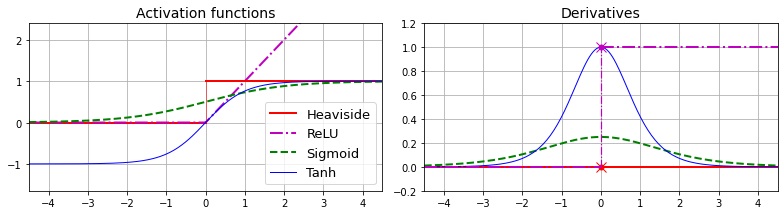

In [10]:
# extra code – this cell generates and saves Figure 10–8

from scipy.special import expit as sigmoid

def relu(z):
    return np.maximum(0, z)

def derivative(f, z, eps=0.000001):
    return (f(z + eps) - f(z - eps))/(2 * eps)

max_z = 4.5
z = np.linspace(-max_z, max_z, 200)

plt.figure(figsize=(11, 3.1))

plt.subplot(121)
plt.plot([-max_z, 0], [0, 0], "r-", linewidth=2, label="Heaviside")
plt.plot(z, relu(z), "m-.", linewidth=2, label="ReLU")
plt.plot([0, 0], [0, 1], "r-", linewidth=0.5)
plt.plot([0, max_z], [1, 1], "r-", linewidth=2)
plt.plot(z, sigmoid(z), "g--", linewidth=2, label="Sigmoid")
plt.plot(z, np.tanh(z), "b-", linewidth=1, label="Tanh")
plt.grid(True)
plt.title("Activation functions")
plt.axis([-max_z, max_z, -1.65, 2.4])
plt.gca().set_yticks([-1, 0, 1, 2])
plt.legend(loc="lower right", fontsize=13)

plt.subplot(122)
plt.plot(z, derivative(np.sign, z), "r-", linewidth=2, label="Heaviside")
plt.plot(0, 0, "ro", markersize=5)
plt.plot(0, 0, "rx", markersize=10)
plt.plot(z, derivative(sigmoid, z), "g--", linewidth=2, label="Sigmoid")
plt.plot(z, derivative(np.tanh, z), "b-", linewidth=1, label="Tanh")
plt.plot([-max_z, 0], [0, 0], "m-.", linewidth=2)
plt.plot([0, max_z], [1, 1], "m-.", linewidth=2)
plt.plot([0, 0], [0, 1], "m-.", linewidth=1.2)
plt.plot(0, 1, "mo", markersize=5)
plt.plot(0, 1, "mx", markersize=10)
plt.grid(True)
plt.title("Derivatives")
plt.axis([-max_z, max_z, -0.2, 1.2])

save_fig("activation_functions_plot")
plt.show()

## Regression MLPs

- Three hidden layers
- Each with 50 nodes
- Default (ReLu) activation function for each layer 
- Weights are are initially random values between -1 and 1
- We take the California data seen earlier and scale it
- We learn the new weights from the training data, using the training responses to measure errors
- We predict the prices for the locations in the validation data
    - and compare to the actual prices when calculating MSE

In [11]:
%%time
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = mean_squared_error(y_valid, y_pred, squared=False)

CPU times: user 1min 15s, sys: 548 ms, total: 1min 15s
Wall time: 10.1 s


In [12]:
rmse

0.5053326657968588

- MSE is similar that for a Randon Forest model
- We have done no CVC, no overfit/undefit tradeoff, etc.
- *sklearn* has a basic MLP implentation that works well for many problems
    - but which lacks the sophisticated additional elements that we see in *Keras*

## Classification MLPs

- Simple code to classify the Iris flower dataset
- One hidden layer with 5 nodes
- Default MLP settings
- We scale before learning new weights, as before
- We get 100% accuracy on the validation set
    - which is clear evidence of overfit
- Note that 3-class problems are easily handled
    - the model returns three probablities that sum to one
    - we take the largest as out predicted class
    - the output layer uses **softmax** activation to do this

In [13]:
# extra code – this was left as an exercise for the reader

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

iris = load_iris()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, test_size=0.1, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42)

mlp_clf = MLPClassifier(hidden_layer_sizes=[5], max_iter=10_000,
                        random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_clf)
pipeline.fit(X_train, y_train)
accuracy = pipeline.score(X_valid, y_valid)
accuracy

1.0

# Implementing MLPs with Keras

- Keras is the high-level **deep learning** API in TensorFlow
- Deep learning has many definitions
    - for us it means many and/or complex hidden layers
    
## Building an Image Classifier Using the Sequential API
### Using Keras to load the dataset

Let's start by loading the fashion MNIST dataset. Keras has a number of functions to load popular datasets in `tf.keras.datasets`. The dataset is already split for you between a training set (60,000 images) and a test set (10,000 images), but it can be useful to split the training set further to have a validation set. We'll use 55,000 images for training, and 5,000 for validation.

- Note the data split
- 60k used to train the MLP
    - 55k for actual training
    - 5k for evaluating the training at each stage
- 10k holdout test data
    - never used at any stage of the training
    - predicting theses instances will supply our estimate of the generalisation error for our model
    - i.e. the error when used to predict images that we don't yet know about

In [14]:
import tensorflow as tf

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

The training set contains 60,000 grayscale images, each 28x28 pixels:

In [15]:
X_train.shape

(55000, 28, 28)

Each pixel intensity is represented as a byte (0 to 255):

In [16]:
X_train.dtype

dtype('uint8')

- We always scale data before learning a NN
    - never a disadvantage
    - often a large advantage

Let's scale the pixel intensities down to the 0-1 range and convert them to floats, by dividing by 255:

In [17]:
X_train, X_valid, X_test = X_train / 255., X_valid / 255., X_test / 255.

You can plot an image using Matplotlib's `imshow()` function, with a `'binary'`
 color map:

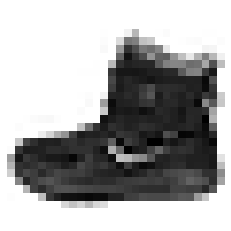

In [18]:
# extra code

plt.imshow(X_train[0], cmap="binary")
plt.axis('off')
plt.show()

The labels are the class IDs (represented as uint8), from 0 to 9:

In [19]:
y_train

array([9, 0, 0, ..., 9, 0, 2], dtype=uint8)

Here are the corresponding class names:

In [20]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

So the first image in the training set is an ankle boot:

In [21]:
class_names[y_train[0]]

'Ankle boot'

Let's take a look at a sample of the images in the dataset:

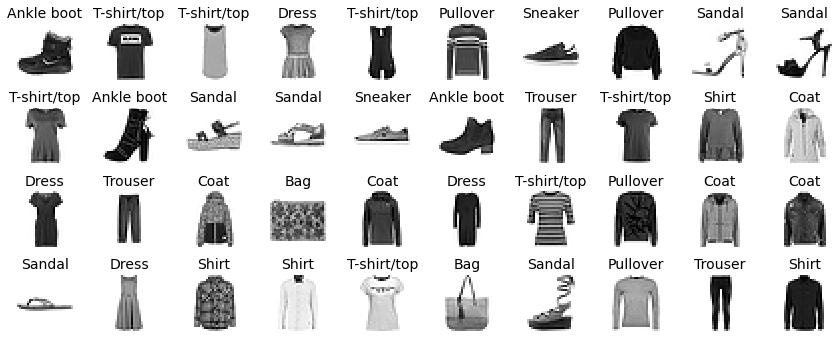

In [22]:
# extra code – this cell generates and saves Figure 10–10

n_rows = 4
n_cols = 10
plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))
for row in range(n_rows):
    for col in range(n_cols):
        index = n_cols * row + col
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(X_train[index], cmap="binary", interpolation="nearest")
        plt.axis('off')
        plt.title(class_names[y_train[index]])
plt.subplots_adjust(wspace=0.2, hspace=0.5)

save_fig("fashion_mnist_plot")
plt.show()

### Creating the model using the Sequential API

- Sequential groups a linear stack of layers into a *tf.keras.Model*
- We use a random seed to reproduce results as the weights are initialised to random values
- The input data is in two dimensions (pixel row and column) so we flatten into a single dimension of size $26 \times 28 = 784$
- We define each hidden layer in terms of its size and the activation function used
- The output layer will use **softmax** to produce 10 probablities that sum to one

In [23]:
tf.random.set_seed(42)
model = tf.keras.Sequential()
model.add(tf.keras.layers.InputLayer(input_shape=[28, 28]))
model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(300, activation="relu"))
model.add(tf.keras.layers.Dense(100, activation="relu"))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

In [24]:
# extra code – clear the session to reset the name counters
tf.keras.backend.clear_session()
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

- There are two ways to show the architecture 
- These are useful when planning, comparing and experimenting with different potential architectures

In [25]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 300)               235500    
                                                                 
 dense_1 (Dense)             (None, 100)               30100     
                                                                 
 dense_2 (Dense)             (None, 10)                1010      
                                                                 
Total params: 266610 (1.02 MB)
Trainable params: 266610 (1.02 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [26]:
# extra code – another way to display the model's architecture
tf.keras.utils.plot_model(model, "my_fashion_mnist_model.png", show_shapes=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [27]:
model.layers

In [28]:
hidden1 = model.layers[1]
hidden1.name

'dense'

In [29]:
model.get_layer('dense') is hidden1

True

- We can check that the initial wieghts are random values between -1 and 1
- And that the bias terms are initialised to zero

In [30]:
weights, biases = hidden1.get_weights()
weights

array([[-0.04804468, -0.02302391, -0.03088536, ..., -0.06369257,
         0.06373645,  0.0352937 ],
       [-0.01117059, -0.04238616,  0.03864623, ..., -0.04369078,
        -0.02749044,  0.0710101 ],
       [-0.01972153,  0.02352405, -0.05878074, ...,  0.04468942,
         0.03489414,  0.03400099],
       ...,
       [-0.03362491, -0.04117829, -0.04404581, ...,  0.0340123 ,
         0.0591788 , -0.02921857],
       [-0.04775344,  0.05419604,  0.04664951, ..., -0.03888111,
        -0.01442597,  0.04246008],
       [ 0.05024534,  0.03262714,  0.05035833, ...,  0.04445211,
        -0.07238066,  0.01488899]], dtype=float32)

In [31]:
weights.shape

(784, 300)

In [32]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [33]:
biases.shape

(300,)

### Compiling the model

- We need to specify our notion of error to derive the model
    - called the **loss** function
- Keras has about 60 different metrics that can be used
    - here another possible choice would be *categorical_crossentropy* as we have a multiclass problem
- For binary callsification we'd specify *sigmoid* at the output layer and use *binary_crossentropy*
- We also specify the method used to get improved weights from the initial weights
    - here we use the Stochastic Gradient Descent that we saw in earlier topics
    - as long as the local error surface is roughly quadratic everything should be fine
- Our preferred metric for predictive performance is accuracy
     - but could be F1-score, PPV, etc.
    

In [34]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

This is equivalent to:

In [35]:
# extra code – this cell is equivalent to the previous cell
model.compile(loss=tf.keras.losses.sparse_categorical_crossentropy,
              optimizer=tf.keras.optimizers.SGD(),
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])

In [36]:
# extra code – shows how to convert class ids to one-hot vectors
tf.keras.utils.to_categorical([0, 5, 1, 0], num_classes=10)

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

Note: it's important to set `num_classes` when the number of classes is greater than the maximum class id in the sample.

In [37]:
# extra code – shows how to convert one-hot vectors to class ids
np.argmax(
    [[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
     [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
     [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
     [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.]],
    axis=1
)

array([0, 5, 1, 0])

### Training and evaluating the model

- An **epoch** is one interation of the process that measures loss with current set of weights and tries to find weights that will reduce the loss

In [38]:
%%time
history = model.fit(X_train, y_train, epochs=30,
                    validation_data=(X_valid, y_valid))

Epoch 1/30
1719/1719 [==============================] - 2s 963us/step - loss: 0.7076 - sparse_categorical_accuracy: 0.7677 - val_loss: 0.5035 - val_sparse_categorical_accuracy: 0.8244
Epoch 2/30
1719/1719 [==============================] - 2s 894us/step - loss: 0.4883 - sparse_categorical_accuracy: 0.8298 - val_loss: 0.4607 - val_sparse_categorical_accuracy: 0.8334
Epoch 3/30
1719/1719 [==============================] - 2s 893us/step - loss: 0.4418 - sparse_categorical_accuracy: 0.8448 - val_loss: 0.4250 - val_sparse_categorical_accuracy: 0.8548
Epoch 4/30
1719/1719 [==============================] - 2s 902us/step - loss: 0.4168 - sparse_categorical_accuracy: 0.8553 - val_loss: 0.3978 - val_sparse_categorical_accuracy: 0.8622
Epoch 5/30
1719/1719 [==============================] - 2s 913us/step - loss: 0.3955 - sparse_categorical_accuracy: 0.8615 - val_loss: 0.3920 - val_sparse_categorical_accuracy: 0.8622
Epoch 6/30
1719/1719 [==============================] - 2s 915us/step - loss: 0.

In [39]:
history.params

{'verbose': 1, 'epochs': 30, 'steps': 1719}

In [40]:
print(history.epoch)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


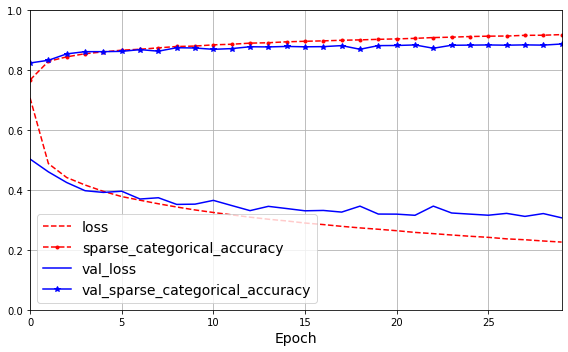

In [41]:
import matplotlib.pyplot as plt
import pandas as pd

pd.DataFrame(history.history).plot(
    figsize=(8, 5), xlim=[0, 29], ylim=[0, 1], grid=True, xlabel="Epoch",
    style=["r--", "r--.", "b-", "b-*"])
plt.legend(loc="lower left")  # extra code
save_fig("keras_learning_curves_plot")  # extra code
plt.show()

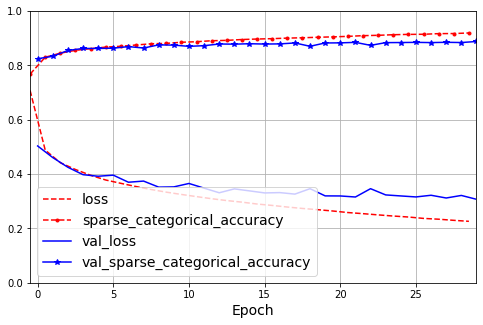

In [42]:
# extra code – shows how to shift the training curve by -1/2 epoch
plt.figure(figsize=(8, 5))
for key, style in zip(history.history, ["r--", "r--.", "b-", "b-*"]):
    epochs = np.array(history.epoch) + (0 if key.startswith("val_") else -0.5)
    plt.plot(epochs, history.history[key], style, label=key)
plt.xlabel("Epoch")
plt.axis([-0.5, 29, 0., 1])
plt.legend(loc="lower left")
plt.grid()
plt.show()

- How do we interpret this (very important) chart?
    - the terminology can be confusing
- The test and training accuracy (using the sparse_categorical_crossentropy metric) both increase during training
- The test and train loss (using sparse_categorical_crossentropy) are both falling
- This shows that our ability to predict data not used to learn weights has improved
    - and would probably continue to improve if we ran a few more epochs
- The gap between the loss curves indicates some overfit
    - as does the gap between the accuracy curves
- But the final accuracy on the 10k holdout test instances is pretty good

In [43]:
model.evaluate(X_test, y_test)

313/313 [==============================] - 0s 521us/step - loss: 0.3209 - sparse_categorical_accuracy: 0.8867


[0.3208511173725128, 0.8866999745368958]

### Using the model to make predictions

- Predictions are 10 probabilities that sum to one
    - we simply take the largest as our prediction

In [44]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 [==============================] - 0s 34ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.01, 0.  , 0.02, 0.  , 0.97],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [45]:
y_pred = y_proba.argmax(axis=-1)
y_pred

array([9, 2, 1])

In [46]:
np.array(class_names)[y_pred]

array(['Ankle boot', 'Pullover', 'Trouser'], dtype='<U11')

In [47]:
y_new = y_test[:3]
y_new

array([9, 2, 1], dtype=uint8)

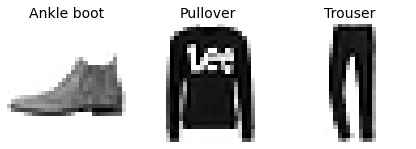

In [48]:
# extra code – this cell generates and saves Figure 10–12
plt.figure(figsize=(7.2, 2.4))
for index, image in enumerate(X_new):
    plt.subplot(1, 3, index + 1)
    plt.imshow(image, cmap="binary", interpolation="nearest")
    plt.axis('off')
    plt.title(class_names[y_test[index]])
plt.subplots_adjust(wspace=0.2, hspace=0.5)
save_fig('fashion_mnist_images_plot', tight_layout=False)
plt.show()

## Building a Regression MLP Using the Sequential API


Let's load, split and scale the California housing dataset (the original one, not the modified one as in chapter 2):

In [49]:
# extra code – load and split the California housing dataset, like earlier
housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

In [50]:
%%time
tf.random.set_seed(42)
norm_layer = tf.keras.layers.Normalization(input_shape=X_train.shape[1:])
model = tf.keras.Sequential([
    norm_layer,
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(1)
])
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["RootMeanSquaredError"])
norm_layer.adapt(X_train)
history = model.fit(X_train, y_train, epochs=20,
                    validation_data=(X_valid, y_valid))
mse_test, rmse_test = model.evaluate(X_test, y_test)
X_new = X_test[:3]
y_pred = model.predict(X_new)

Epoch 1/20
363/363 [==============================] - 0s 785us/step - loss: 0.8580 - root_mean_squared_error: 0.9263 - val_loss: 0.4239 - val_root_mean_squared_error: 0.6510
Epoch 2/20
363/363 [==============================] - 0s 655us/step - loss: 0.3780 - root_mean_squared_error: 0.6148 - val_loss: 1.2233 - val_root_mean_squared_error: 1.1060
Epoch 3/20
363/363 [==============================] - 0s 645us/step - loss: 0.3727 - root_mean_squared_error: 0.6105 - val_loss: 0.5678 - val_root_mean_squared_error: 0.7535
Epoch 4/20
363/363 [==============================] - 0s 661us/step - loss: 0.3403 - root_mean_squared_error: 0.5833 - val_loss: 1.1389 - val_root_mean_squared_error: 1.0672
Epoch 5/20
363/363 [==============================] - 0s 659us/step - loss: 0.3304 - root_mean_squared_error: 0.5748 - val_loss: 1.7770 - val_root_mean_squared_error: 1.3330
Epoch 6/20
363/363 [==============================] - 0s 661us/step - loss: 0.3246 - root_mean_squared_error: 0.5698 - val_loss: 0

In [51]:
rmse_test

0.5266687273979187

In [52]:
y_pred

array([[0.4552647],
       [1.3174461],
       [4.818929 ]], dtype=float32)

## Building Complex Models Using the Functional API

Not all neural network models are simply sequential. Some may have complex topologies. Some may have multiple inputs and/or multiple outputs. For example, a Wide & Deep neural network (see [paper](https://ai.google/research/pubs/pub45413)) connects all or part of the inputs directly to the output layer.

- The idea behind this technique is that we are trying to find underlying features of the data that are important for predicting new instances
- Some of these might be complex and hard to tease out
    - using many hidden layers will often solve this issue
- But others may be quite simple to identify
    - and forcing all the data through many large layers could lead to distortion that loses this 
    
Still using the housing data:
- We add a normalisation layer that lets us modify the path taken by the inputs through the layers
- And a concatenation layer that adds the wide and deep streams together in an organised way
- All the inputs go through the **deep** architecture
    - i.e. through all the hidden layers
- And also go through the **wide** architecture
    - straight from normalisation to concatenation

In [53]:
# extra code – reset the name counters and make the code reproducible
tf.keras.backend.clear_session()
tf.random.set_seed(42)

In [54]:
normalization_layer = tf.keras.layers.Normalization()
hidden_layer1 = tf.keras.layers.Dense(30, activation="relu")
hidden_layer2 = tf.keras.layers.Dense(30, activation="relu")
concat_layer = tf.keras.layers.Concatenate()
output_layer = tf.keras.layers.Dense(1)

input_ = tf.keras.layers.Input(shape=X_train.shape[1:])
normalized = normalization_layer(input_)
hidden1 = hidden_layer1(normalized)
hidden2 = hidden_layer2(hidden1)
concat = concat_layer([normalized, hidden2])
output = output_layer(concat)

model = tf.keras.Model(inputs=[input_], outputs=[output])

In [55]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 8)]                  0         []                            
                                                                                                  
 normalization (Normalizati  (None, 8)                    17        ['input_1[0][0]']             
 on)                                                                                              
                                                                                                  
 dense (Dense)               (None, 30)                   270       ['normalization[0][0]']       
                                                                                                  
 dense_1 (Dense)             (None, 30)                   930       ['dense[0][0]']           

In [56]:
%%time
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["RootMeanSquaredError"])
normalization_layer.adapt(X_train)
history = model.fit(X_train, y_train, epochs=20,
                    validation_data=(X_valid, y_valid))
mse_test = model.evaluate(X_test, y_test)
y_pred = model.predict(X_new)

Epoch 1/20
363/363 [==============================] - 0s 696us/step - loss: 1.4036 - root_mean_squared_error: 1.1847 - val_loss: 0.5052 - val_root_mean_squared_error: 0.7108
Epoch 2/20
363/363 [==============================] - 0s 543us/step - loss: 0.4464 - root_mean_squared_error: 0.6682 - val_loss: 0.9166 - val_root_mean_squared_error: 0.9574
Epoch 3/20
363/363 [==============================] - 0s 549us/step - loss: 0.3958 - root_mean_squared_error: 0.6291 - val_loss: 0.3588 - val_root_mean_squared_error: 0.5990
Epoch 4/20
363/363 [==============================] - 0s 542us/step - loss: 0.3703 - root_mean_squared_error: 0.6085 - val_loss: 0.3437 - val_root_mean_squared_error: 0.5862
Epoch 5/20
363/363 [==============================] - 0s 567us/step - loss: 0.3605 - root_mean_squared_error: 0.6004 - val_loss: 0.5078 - val_root_mean_squared_error: 0.7126
Epoch 6/20
363/363 [==============================] - 0s 546us/step - loss: 0.3548 - root_mean_squared_error: 0.5956 - val_loss: 1

What if you want to send different subsets of input features through the wide or deep paths? We will send 5 features (features 0 to 4), and 6 through the deep path (features 2 to 7). Note that 3 features will go through both (features 2, 3 and 4).

In [57]:
tf.random.set_seed(42)  # extra code

In [58]:
input_wide = tf.keras.layers.Input(shape=[5])  # features 0 to 4
input_deep = tf.keras.layers.Input(shape=[6])  # features 2 to 7
norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()
norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)
hidden1 = tf.keras.layers.Dense(30, activation="relu")(norm_deep)
hidden2 = tf.keras.layers.Dense(30, activation="relu")(hidden1)
concat = tf.keras.layers.concatenate([norm_wide, hidden2])
output = tf.keras.layers.Dense(1)(concat)
model = tf.keras.Model(inputs=[input_wide, input_deep], outputs=[output])

In [59]:
%%time
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["RootMeanSquaredError"])

X_train_wide, X_train_deep = X_train[:, :5], X_train[:, 2:]
X_valid_wide, X_valid_deep = X_valid[:, :5], X_valid[:, 2:]
X_test_wide, X_test_deep = X_test[:, :5], X_test[:, 2:]
X_new_wide, X_new_deep = X_test_wide[:3], X_test_deep[:3]

norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)
history = model.fit((X_train_wide, X_train_deep), y_train, epochs=20,
                    validation_data=((X_valid_wide, X_valid_deep), y_valid))
mse_test = model.evaluate((X_test_wide, X_test_deep), y_test)
y_pred = model.predict((X_new_wide, X_new_deep))

Epoch 1/20
363/363 [==============================] - 0s 720us/step - loss: 1.3272 - root_mean_squared_error: 1.1520 - val_loss: 1.6060 - val_root_mean_squared_error: 1.2673
Epoch 2/20
363/363 [==============================] - 0s 584us/step - loss: 0.4816 - root_mean_squared_error: 0.6940 - val_loss: 0.5713 - val_root_mean_squared_error: 0.7558
Epoch 3/20
363/363 [==============================] - 0s 581us/step - loss: 0.4311 - root_mean_squared_error: 0.6566 - val_loss: 0.4626 - val_root_mean_squared_error: 0.6801
Epoch 4/20
363/363 [==============================] - 0s 604us/step - loss: 0.4152 - root_mean_squared_error: 0.6444 - val_loss: 0.4048 - val_root_mean_squared_error: 0.6362
Epoch 5/20
363/363 [==============================] - 0s 578us/step - loss: 0.4032 - root_mean_squared_error: 0.6350 - val_loss: 0.3736 - val_root_mean_squared_error: 0.6112
Epoch 6/20
363/363 [==============================] - 0s 573us/step - loss: 0.3924 - root_mean_squared_error: 0.6264 - val_loss: 0

- When is wide & deep useful?
- One case is to check that the deep path is learning something useful
- We can compare losses from the two output layers to ensure that we are not overfitting
- Note that here we weight the losses 90-10
    - more weight to the full wide & deep model
    - less weight to the auxilary checking model

Adding an auxiliary output for regularization:

In [60]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

In [61]:
input_wide = tf.keras.layers.Input(shape=[5])  # features 0 to 4
input_deep = tf.keras.layers.Input(shape=[6])  # features 2 to 7
norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()
norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)
hidden1 = tf.keras.layers.Dense(30, activation="relu")(norm_deep)
hidden2 = tf.keras.layers.Dense(30, activation="relu")(hidden1)
concat = tf.keras.layers.concatenate([norm_wide, hidden2])
output = tf.keras.layers.Dense(1)(concat)
aux_output = tf.keras.layers.Dense(1)(hidden2)
model = tf.keras.Model(inputs=[input_wide, input_deep],
                       outputs=[output, aux_output])

In [62]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss=("mse", "mse"), loss_weights=(0.9, 0.1), optimizer=optimizer,
              metrics=["RootMeanSquaredError"])

In [63]:
%%time
norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)
history = model.fit(
    (X_train_wide, X_train_deep), (y_train, y_train), epochs=20,
    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid))
)

Epoch 1/20
363/363 [==============================] - 0s 868us/step - loss: 1.8516 - dense_2_loss: 1.7781 - dense_3_loss: 2.5133 - dense_2_root_mean_squared_error: 1.3334 - dense_3_root_mean_squared_error: 1.5854 - val_loss: 1.8243 - val_dense_2_loss: 1.6009 - val_dense_3_loss: 3.8354 - val_dense_2_root_mean_squared_error: 1.2653 - val_dense_3_root_mean_squared_error: 1.9584
Epoch 2/20
363/363 [==============================] - 0s 657us/step - loss: 0.6102 - dense_2_loss: 0.5815 - dense_3_loss: 0.8687 - dense_2_root_mean_squared_error: 0.7625 - dense_3_root_mean_squared_error: 0.9321 - val_loss: 1.0084 - val_dense_2_loss: 0.9180 - val_dense_3_loss: 1.8220 - val_dense_2_root_mean_squared_error: 0.9581 - val_dense_3_root_mean_squared_error: 1.3498
Epoch 3/20
363/363 [==============================] - 0s 667us/step - loss: 0.4820 - dense_2_loss: 0.4671 - dense_3_loss: 0.6158 - dense_2_root_mean_squared_error: 0.6835 - dense_3_root_mean_squared_error: 0.7847 - val_loss: 0.4346 - val_dense_

- Check that the losses and errors are similar for both paths through the architecture
- If the auxiliary error is much smaller than the whole error, then the deep path is contributing to overfit

In [64]:
eval_results = model.evaluate((X_test_wide, X_test_deep), (y_test, y_test))
weighted_sum_of_losses, main_loss, aux_loss, main_rmse, aux_rmse = eval_results

162/162 [==============================] - 0s 421us/step - loss: 0.3319 - dense_2_loss: 0.3256 - dense_3_loss: 0.3887 - dense_2_root_mean_squared_error: 0.5706 - dense_3_root_mean_squared_error: 0.6234


- Prediction returns two values, one for wide and the other for deep

In [65]:
y_pred_main, y_pred_aux = model.predict((X_new_wide, X_new_deep))

1/1 [==============================] - 0s 27ms/step


In [66]:
y_pred_tuple = model.predict((X_new_wide, X_new_deep))
y_pred = dict(zip(model.output_names, y_pred_tuple))

1/1 [==============================] - 0s 8ms/step


## Using the Subclassing API to Build Dynamic Models

- A more organised approach to writing code
- Imperative rather than declarative
    - so far we declared the specifics of each MLP model
    - but this is static, so each modification repeats a lot of code
- Keras has a *Model* class which we can subclass
    - creating the layers needed 
- And then call to perform the calculations needed

In [67]:
class WideAndDeepModel(tf.keras.Model):
    def __init__(self, units=30, activation="relu", **kwargs):
        super().__init__(**kwargs)  # needed to support naming the model
        self.norm_layer_wide = tf.keras.layers.Normalization()
        self.norm_layer_deep = tf.keras.layers.Normalization()
        self.hidden1 = tf.keras.layers.Dense(units, activation=activation)
        self.hidden2 = tf.keras.layers.Dense(units, activation=activation)
        self.main_output = tf.keras.layers.Dense(1)
        self.aux_output = tf.keras.layers.Dense(1)
        
    def call(self, inputs):
        input_wide, input_deep = inputs
        norm_wide = self.norm_layer_wide(input_wide)
        norm_deep = self.norm_layer_deep(input_deep)
        hidden1 = self.hidden1(norm_deep)
        hidden2 = self.hidden2(hidden1)
        concat = tf.keras.layers.concatenate([norm_wide, hidden2])
        output = self.main_output(concat)
        aux_output = self.aux_output(hidden2)
        return output, aux_output

tf.random.set_seed(42)  # extra code – just for reproducibility
model = WideAndDeepModel(30, activation="relu", name="my_cool_model")

In [68]:
%%time
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", loss_weights=[0.9, 0.1], optimizer=optimizer,
              metrics=["RootMeanSquaredError"])
model.norm_layer_wide.adapt(X_train_wide)
model.norm_layer_deep.adapt(X_train_deep)
history = model.fit(
    (X_train_wide, X_train_deep), (y_train, y_train), epochs=10,
    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)))
eval_results = model.evaluate((X_test_wide, X_test_deep), (y_test, y_test))
weighted_sum_of_losses, main_loss, aux_loss, main_rmse, aux_rmse = eval_results
y_pred_main, y_pred_aux = model.predict((X_new_wide, X_new_deep))

Epoch 1/10
363/363 [==============================] - 1s 862us/step - loss: 1.6497 - output_1_loss: 1.6077 - output_2_loss: 2.0275 - output_1_root_mean_squared_error: 1.2680 - output_2_root_mean_squared_error: 1.4239 - val_loss: 4.0215 - val_output_1_loss: 3.9083 - val_output_2_loss: 5.0397 - val_output_1_root_mean_squared_error: 1.9769 - val_output_2_root_mean_squared_error: 2.2449
Epoch 2/10
363/363 [==============================] - 0s 652us/step - loss: 0.5907 - output_1_loss: 0.5703 - output_2_loss: 0.7748 - output_1_root_mean_squared_error: 0.7552 - output_2_root_mean_squared_error: 0.8802 - val_loss: 2.1433 - val_output_1_loss: 2.1060 - val_output_2_loss: 2.4792 - val_output_1_root_mean_squared_error: 1.4512 - val_output_2_root_mean_squared_error: 1.5746
Epoch 3/10
363/363 [==============================] - 0s 663us/step - loss: 0.4833 - output_1_loss: 0.4679 - output_2_loss: 0.6220 - output_1_root_mean_squared_error: 0.6840 - output_2_root_mean_squared_error: 0.7887 - val_loss:

1/1 [==============================] - 0s 25ms/step
CPU times: user 3.68 s, sys: 732 ms, total: 4.41 s
Wall time: 3.2 s


## Saving and Restoring a Model

In [69]:
# extra code – delete the directory, in case it already exists

import shutil

shutil.rmtree("my_keras_model", ignore_errors=True)

In [70]:
model.save("my_keras_model", save_format="tf")

INFO:tensorflow:Assets written to: my_keras_model/assets


INFO:tensorflow:Assets written to: my_keras_model/assets


In [71]:
# extra code – show the contents of the my_keras_model/ directory
for path in sorted(Path("my_keras_model").glob("**/*")):
    print(path)

my_keras_model/assets
my_keras_model/fingerprint.pb
my_keras_model/keras_metadata.pb
my_keras_model/saved_model.pb
my_keras_model/variables
my_keras_model/variables/variables.data-00000-of-00001
my_keras_model/variables/variables.index


In [72]:
model = tf.keras.models.load_model("my_keras_model")
y_pred_main, y_pred_aux = model.predict((X_new_wide, X_new_deep))

1/1 [==============================] - 0s 26ms/step


In [73]:
model.save_weights("my_weights")

In [74]:
model.load_weights("my_weights")

In [75]:
# extra code – show the list of my_weights.* files
for path in sorted(Path().glob("my_weights.*")):
    print(path)

my_weights.data-00000-of-00001
my_weights.index


## Using Callbacks

- Useful for saving weights at regular stages so that a system failure is not so terrible
- Main use is for early stopping
    - If the validation set is making no progress for some numer of epochs, we stop
    - We use 10 in the code below
    - Stopping after 23 epochs instead of the planned 100

In [76]:
shutil.rmtree("my_checkpoints", ignore_errors=True)  # extra code

In [77]:
%%time
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("my_checkpoints",
                                                   save_weights_only=True)
history = model.fit(
    (X_train_wide, X_train_deep), (y_train, y_train), epochs=10,
    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)),
    callbacks=[checkpoint_cb])

Epoch 1/10
363/363 [==============================] - 1s 941us/step - loss: 0.3475 - output_1_loss: 0.3401 - output_2_loss: 0.4137 - output_1_root_mean_squared_error: 0.5832 - output_2_root_mean_squared_error: 0.6432 - val_loss: 0.4151 - val_output_1_loss: 0.4043 - val_output_2_loss: 0.5128 - val_output_1_root_mean_squared_error: 0.6358 - val_output_2_root_mean_squared_error: 0.7161
Epoch 2/10
363/363 [==============================] - 0s 739us/step - loss: 0.3436 - output_1_loss: 0.3364 - output_2_loss: 0.4086 - output_1_root_mean_squared_error: 0.5800 - output_2_root_mean_squared_error: 0.6392 - val_loss: 0.5675 - val_output_1_loss: 0.5743 - val_output_2_loss: 0.5065 - val_output_1_root_mean_squared_error: 0.7578 - val_output_2_root_mean_squared_error: 0.7117
Epoch 3/10
363/363 [==============================] - 0s 794us/step - loss: 0.3406 - output_1_loss: 0.3337 - output_2_loss: 0.4027 - output_1_root_mean_squared_error: 0.5777 - output_2_root_mean_squared_error: 0.6346 - val_loss:

In [78]:
%%time
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=10,
                                                     restore_best_weights=True)
history = model.fit(
    (X_train_wide, X_train_deep), (y_train, y_train), epochs=100,
    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)),
    callbacks=[checkpoint_cb, early_stopping_cb])

Epoch 1/100
363/363 [==============================] - 0s 865us/step - loss: 0.3315 - output_1_loss: 0.3250 - output_2_loss: 0.3901 - output_1_root_mean_squared_error: 0.5701 - output_2_root_mean_squared_error: 0.6246 - val_loss: 0.7742 - val_output_1_loss: 0.7801 - val_output_2_loss: 0.7209 - val_output_1_root_mean_squared_error: 0.8832 - val_output_2_root_mean_squared_error: 0.8491
Epoch 2/100
363/363 [==============================] - 0s 770us/step - loss: 0.3301 - output_1_loss: 0.3238 - output_2_loss: 0.3861 - output_1_root_mean_squared_error: 0.5691 - output_2_root_mean_squared_error: 0.6214 - val_loss: 0.6214 - val_output_1_loss: 0.6204 - val_output_2_loss: 0.6306 - val_output_1_root_mean_squared_error: 0.7876 - val_output_2_root_mean_squared_error: 0.7941
Epoch 3/100
363/363 [==============================] - 0s 763us/step - loss: 0.3239 - output_1_loss: 0.3178 - output_2_loss: 0.3793 - output_1_root_mean_squared_error: 0.5637 - output_2_root_mean_squared_error: 0.6159 - val_lo

- We can also used checkpointed values to look at the ratios of validation loss to training loss
    - these should be converging to a value close to one

In [79]:
class PrintValTrainRatioCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs):
        ratio = logs["val_loss"] / logs["loss"]
        print(f"Epoch={epoch}, val/train={ratio:.2f}")

In [80]:
%%time
val_train_ratio_cb = PrintValTrainRatioCallback()
history = model.fit(
    (X_train_wide, X_train_deep), (y_train, y_train), epochs=10,
    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)),
    callbacks=[val_train_ratio_cb], verbose=0)

Epoch=0, val/train=0.95
Epoch=1, val/train=1.00
Epoch=2, val/train=1.06
Epoch=3, val/train=2.17
Epoch=4, val/train=1.52
Epoch=5, val/train=1.66
Epoch=6, val/train=1.14
Epoch=7, val/train=1.46
Epoch=8, val/train=1.63
Epoch=9, val/train=1.17
CPU times: user 2.63 s, sys: 588 ms, total: 3.22 s
Wall time: 2.22 s


## Using TensorBoard for Visualization

TensorBoard is preinstalled on Colab, but not the `tensorboard-plugin-profile`, so let's install it:

In [81]:
if "google.colab" in sys.modules:  # extra code
    %pip install -q -U tensorboard-plugin-profile

In [82]:
shutil.rmtree("my_logs", ignore_errors=True)

In [83]:
from pathlib import Path
from time import strftime

def get_run_logdir(root_logdir="my_logs"):
    return Path(root_logdir) / strftime("run_%Y_%m_%d_%H_%M_%S")

run_logdir = get_run_logdir()

In [84]:
# extra code – builds the first regression model we used earlier
tf.keras.backend.clear_session()
tf.random.set_seed(42)
norm_layer = tf.keras.layers.Normalization(input_shape=X_train.shape[1:])
model = tf.keras.Sequential([
    norm_layer,
    tf.keras.layers.Dense(30, activation="relu"),
    tf.keras.layers.Dense(30, activation="relu"),
    tf.keras.layers.Dense(1)
])
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["RootMeanSquaredError"])
norm_layer.adapt(X_train)

In [85]:
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir,
                                                profile_batch=(100, 200))
history = model.fit(X_train, y_train, epochs=20,
                    validation_data=(X_valid, y_valid),
                    callbacks=[tensorboard_cb])

Epoch 1/20


2023-05-26 14:04:26.201265: I tensorflow/tsl/profiler/lib/profiler_session.cc:104] Profiler session initializing.
2023-05-26 14:04:26.201274: I tensorflow/tsl/profiler/lib/profiler_session.cc:119] Profiler session started.
2023-05-26 14:04:26.201294: I tensorflow/tsl/profiler/lib/profiler_session.cc:131] Profiler session tear down.


104/363 [=======>......................] - ETA: 0s - loss: 3.5764 - root_mean_squared_error: 1.8911 

2023-05-26 14:04:26.371863: I tensorflow/tsl/profiler/lib/profiler_session.cc:104] Profiler session initializing.
2023-05-26 14:04:26.371881: I tensorflow/tsl/profiler/lib/profiler_session.cc:119] Profiler session started.


324/363 [=========================>....] - ETA: 0s - loss: 2.2251 - root_mean_squared_error: 1.4917

2023-05-26 14:04:26.417193: I tensorflow/tsl/profiler/lib/profiler_session.cc:70] Profiler session collecting data.
2023-05-26 14:04:26.422217: I tensorflow/tsl/profiler/lib/profiler_session.cc:131] Profiler session tear down.
2023-05-26 14:04:26.423903: I tensorflow/tsl/profiler/rpc/client/save_profile.cc:144] Collecting XSpace to repository: my_logs/run_2023_05_26_14_04_26/plugins/profile/2023_05_26_14_04_26/MCFDQ66WLKPY.xplane.pb


363/363 [==============================] - 0s 714us/step - loss: 2.0937 - root_mean_squared_error: 1.4470 - val_loss: 0.9316 - val_root_mean_squared_error: 0.9652
Epoch 2/20
363/363 [==============================] - 0s 522us/step - loss: 0.7634 - root_mean_squared_error: 0.8737 - val_loss: 0.6629 - val_root_mean_squared_error: 0.8142
Epoch 3/20
363/363 [==============================] - 0s 517us/step - loss: 0.6404 - root_mean_squared_error: 0.8002 - val_loss: 0.6013 - val_root_mean_squared_error: 0.7754
Epoch 4/20
363/363 [==============================] - 0s 518us/step - loss: 0.5932 - root_mean_squared_error: 0.7702 - val_loss: 0.5516 - val_root_mean_squared_error: 0.7427
Epoch 5/20
363/363 [==============================] - 0s 514us/step - loss: 0.5576 - root_mean_squared_error: 0.7467 - val_loss: 0.5182 - val_root_mean_squared_error: 0.7198
Epoch 6/20
363/363 [==============================] - 0s 529us/step - loss: 0.5272 - root_mean_squared_error: 0.7261 - val_loss: 0.4925 - val

In [86]:
print("my_logs")
for path in sorted(Path("my_logs").glob("**/*")):
    print("  " * (len(path.parts) - 1) + path.parts[-1])

my_logs
  run_2023_05_26_14_04_26
    plugins
      profile
        2023_05_26_14_04_26
          MCFDQ66WLKPY.xplane.pb
    train
      events.out.tfevents.1685106266.MCFDQ66WLKPY.23730.0.v2
    validation
      events.out.tfevents.1685106266.MCFDQ66WLKPY.23730.1.v2


Let's load the `tensorboard` Jupyter extension and start the TensorBoard server: 

In [87]:
%load_ext tensorboard
%tensorboard --logdir=./my_logs

**Note**: if you prefer to access TensorBoard in a separate tab, click the "localhost:6006" link below:

In [88]:
# extra code

if "google.colab" in sys.modules:
    from google.colab import output

    output.serve_kernel_port_as_window(6006)
else:
    from IPython.display import display, HTML

    display(HTML('<a href="http://localhost:6006/">http://localhost:6006/</a>'))

# Fine-Tuning Neural Network Hyperparameters

- Specify ranges of options for layers, learning rates, etc
- Randomly search 5 selections, each running 10 epochs
- Save and report the best configuration found so far
- Either keep searching randomly
- Or use the best found so far as a starting point for a usual grid search 

In this section we'll use the Fashion MNIST dataset again:

In [89]:
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

In [90]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

In [91]:
if "google.colab" in sys.modules:
    %pip install -q -U keras_tuner

In [92]:
import keras_tuner as kt

def build_model(hp):
    n_hidden = hp.Int("n_hidden", min_value=0, max_value=8, default=2)
    n_neurons = hp.Int("n_neurons", min_value=16, max_value=256)
    learning_rate = hp.Float("learning_rate", min_value=1e-4, max_value=1e-2,
                             sampling="log")
    optimizer = hp.Choice("optimizer", values=["sgd", "adam"])
    if optimizer == "sgd":
        optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate)
    else:
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Flatten())
    for _ in range(n_hidden):
        model.add(tf.keras.layers.Dense(n_neurons, activation="relu"))
    model.add(tf.keras.layers.Dense(10, activation="softmax"))
    model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
                  metrics=["accuracy"])
    return model

In [93]:
%%time
random_search_tuner = kt.RandomSearch(
    build_model, objective="val_accuracy", max_trials=5, overwrite=True,
    directory="my_fashion_mnist", project_name="my_rnd_search", seed=42)
random_search_tuner.search(X_train, y_train, epochs=10,
                           validation_data=(X_valid, y_valid))

Trial 5 Complete [00h 00m 11s]
val_accuracy: 0.8392000198364258

Best val_accuracy So Far: 0.8574000000953674
Total elapsed time: 00h 01m 02s
INFO:tensorflow:Oracle triggered exit


INFO:tensorflow:Oracle triggered exit


CPU times: user 1min 13s, sys: 19.5 s, total: 1min 33s
Wall time: 1min 2s


In [94]:
top3_models = random_search_tuner.get_best_models(num_models=3)
best_model = top3_models[0]

In [95]:
top3_params = random_search_tuner.get_best_hyperparameters(num_trials=3)
top3_params[0].values  # best hyperparameter values

{'n_hidden': 7,
 'n_neurons': 100,
 'learning_rate': 0.0012482904754698163,
 'optimizer': 'sgd'}

In [96]:
best_trial = random_search_tuner.oracle.get_best_trials(num_trials=1)[0]
best_trial.summary()

Trial 1 summary
Hyperparameters:
n_hidden: 7
n_neurons: 100
learning_rate: 0.0012482904754698163
optimizer: sgd
Score: 0.8574000000953674


In [97]:
best_trial.metrics.get_last_value("val_accuracy")

0.8574000000953674

In [98]:
best_model.fit(X_train_full, y_train_full, epochs=10)
test_loss, test_accuracy = best_model.evaluate(X_test, y_test)

Epoch 1/10
1875/1875 [==============================] - 2s 756us/step - loss: 0.3337 - accuracy: 0.8779
Epoch 2/10
1875/1875 [==============================] - 1s 754us/step - loss: 0.3224 - accuracy: 0.8810
Epoch 3/10
1875/1875 [==============================] - 1s 769us/step - loss: 0.3130 - accuracy: 0.8833
Epoch 4/10
1875/1875 [==============================] - 1s 781us/step - loss: 0.3054 - accuracy: 0.8877
Epoch 5/10
1875/1875 [==============================] - 1s 775us/step - loss: 0.2986 - accuracy: 0.8895
Epoch 6/10
1875/1875 [==============================] - 1s 770us/step - loss: 0.2920 - accuracy: 0.8903
Epoch 7/10
1875/1875 [==============================] - 1s 770us/step - loss: 0.2858 - accuracy: 0.8942
Epoch 8/10
1875/1875 [==============================] - 1s 762us/step - loss: 0.2798 - accuracy: 0.8959
Epoch 9/10
1875/1875 [==============================] - 1s 754us/step - loss: 0.2743 - accuracy: 0.8978
Epoch 10/10
313/313 [==============================] - 0s 475us/

### Other methods

- HyperModel
    - similar to the above but with improved memory handling
- BaysianOptimization
    - cutting edge
    - currently an active area of research
    - instead of just random, the method attempts to converge on good values
    - the bad news is the method has its own hyperparameters

In [99]:
class MyClassificationHyperModel(kt.HyperModel):
    def build(self, hp):
        return build_model(hp)

    def fit(self, hp, model, X, y, **kwargs):
        if hp.Boolean("normalize"):
            norm_layer = tf.keras.layers.Normalization()
            X = norm_layer(X)
        return model.fit(X, y, **kwargs)

In [100]:
hyperband_tuner = kt.Hyperband(
    MyClassificationHyperModel(), objective="val_accuracy", seed=42,
    max_epochs=10, factor=3, hyperband_iterations=2,
    overwrite=True, directory="my_fashion_mnist", project_name="hyperband")

In [101]:
%%time
root_logdir = Path(hyperband_tuner.project_dir) / "tensorboard"
tensorboard_cb = tf.keras.callbacks.TensorBoard(root_logdir)
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=2)
hyperband_tuner.search(X_train, y_train, epochs=10,
                       validation_data=(X_valid, y_valid),
                       callbacks=[early_stopping_cb, tensorboard_cb])

Trial 60 Complete [00h 00m 13s]
val_accuracy: 0.8537999987602234

Best val_accuracy So Far: 0.8845999836921692
Total elapsed time: 00h 07m 31s
INFO:tensorflow:Oracle triggered exit


INFO:tensorflow:Oracle triggered exit


CPU times: user 9min 48s, sys: 3min 4s, total: 12min 52s
Wall time: 7min 30s


In [102]:
%%time
bayesian_opt_tuner = kt.BayesianOptimization(
    MyClassificationHyperModel(), objective="val_accuracy", seed=42,
    max_trials=10, alpha=1e-4, beta=2.6,
    overwrite=True, directory="my_fashion_mnist", project_name="bayesian_opt")
bayesian_opt_tuner.search(X_train, y_train, epochs=10,
                          validation_data=(X_valid, y_valid),
                          callbacks=[early_stopping_cb])

Trial 10 Complete [00h 00m 11s]
val_accuracy: 0.840399980545044

Best val_accuracy So Far: 0.8587999939918518
Total elapsed time: 00h 01m 48s
INFO:tensorflow:Oracle triggered exit


INFO:tensorflow:Oracle triggered exit


CPU times: user 2min 24s, sys: 45.5 s, total: 3min 10s
Wall time: 1min 48s


In [103]:
%tensorboard --logdir {root_logdir}

ERROR: Failed to launch TensorBoard (exited with 1).
Contents of stderr:
Address already in use
Port 6006 is in use by another program. Either identify and stop that program, or start the server with a different port.

# Exercise solutions

## 1. to 9.

1. Visit the [TensorFlow Playground](https://playground.tensorflow.org/) and play around with it, as described in this exercise.
2. Here is a neural network based on the original artificial neurons that computes _A_ ⊕ _B_ (where ⊕ represents the exclusive OR), using the fact that _A_ ⊕ _B_ = (_A_ ∧ ¬ _B_) ∨ (¬ _A_ ∧ _B_). There are other solutions—for example, using the fact that _A_ ⊕ _B_ = (_A_ ∨ _B_) ∧ ¬(_A_ ∧ _B_), or the fact that _A_ ⊕ _B_ = (_A_ ∨ _B_) ∧ (¬ _A_ ∨ ¬ _B_), and so on.<br /><img width="70%" src="images/ann/exercise2.png" />
3. A classical Perceptron will converge only if the dataset is linearly separable, and it won't be able to estimate class probabilities. In contrast, a Logistic Regression classifier will generally converge to a reasonably good solution even if the dataset is not linearly separable, and it will output class probabilities. If you change the Perceptron's activation function to the sigmoid activation function (or the softmax activation function if there are multiple neurons), and if you train it using Gradient Descent (or some other optimization algorithm minimizing the cost function, typically cross entropy), then it becomes equivalent to a Logistic Regression classifier.
4. The sigmoid activation function was a key ingredient in training the first MLPs because its derivative is always nonzero, so Gradient Descent can always roll down the slope. When the activation function is a step function, Gradient Descent cannot move, as there is no slope at all.
5. Popular activation functions include the step function, the sigmoid function, the hyperbolic tangent (tanh) function, and the Rectified Linear Unit (ReLU) function (see Figure 10-8). See Chapter 11 for other examples, such as ELU and variants of the ReLU function.
6. Considering the MLP described in the question, composed of one input layer with 10 passthrough neurons, followed by one hidden layer with 50 artificial neurons, and finally one output layer with 3 artificial neurons, where all artificial neurons use the ReLU activation function:
    * The shape of the input matrix **X** is _m_ × 10, where _m_ represents the training batch size.
    * The shape of the hidden layer's weight matrix **W**<sub>_h_</sub> is 10 × 50, and the length of its bias vector **b**<sub>_h_</sub> is 50.
    * The shape of the output layer's weight matrix **W**<sub>_o_</sub> is 50 × 3, and the length of its bias vector **b**<sub>_o_</sub> is 3.
    * The shape of the network's output matrix **Y** is _m_ × 3.
    * **Y** = ReLU(ReLU(**X** **W**<sub>_h_</sub> + **b**<sub>_h_</sub>) **W**<sub>_o_</sub> + **b**<sub>_o_</sub>). Recall that the ReLU function just sets every negative number in the matrix to zero. Also note that when you are adding a bias vector to a matrix, it is added to every single row in the matrix, which is called _broadcasting_.
7. To classify email into spam or ham, you just need one neuron in the output layer of a neural network—for example, indicating the probability that the email is spam. You would typically use the sigmoid activation function in the output layer when estimating a probability. If instead you want to tackle MNIST, you need 10 neurons in the output layer, and you must replace the sigmoid function with the softmax activation function, which can handle multiple classes, outputting one probability per class. If you want your neural network to predict housing prices like in Chapter 2, then you need one output neuron, using no activation function at all in the output layer. Note: when the values to predict can vary by many orders of magnitude, you may want to predict the logarithm of the target value rather than the target value directly. Simply computing the exponential of the neural network's output will give you the estimated value (since exp(log _v_) = _v_).
8. Backpropagation is a technique used to train artificial neural networks. It first computes the gradients of the cost function with regard to every model parameter (all the weights and biases), then it performs a Gradient Descent step using these gradients. This backpropagation step is typically performed thousands or millions of times, using many training batches, until the model parameters converge to values that (hopefully) minimize the cost function. To compute the gradients, backpropagation uses reverse-mode autodiff (although it wasn't called that when backpropagation was invented, and it has been reinvented several times). Reverse-mode autodiff performs a forward pass through a computation graph, computing every node's value for the current training batch, and then it performs a reverse pass, computing all the gradients at once (see Appendix B for more details). So what's the difference? Well, backpropagation refers to the whole process of training an artificial neural network using multiple backpropagation steps, each of which computes gradients and uses them to perform a Gradient Descent step. In contrast, reverse-mode autodiff is just a technique to compute gradients efficiently, and it happens to be used by backpropagation.
9. Here is a list of all the hyperparameters you can tweak in a basic MLP: the number of hidden layers, the number of neurons in each hidden layer, and the activation function used in each hidden layer and in the output layer. In general, the ReLU activation function (or one of its variants; see Chapter 11) is a good default for the hidden layers. For the output layer, in general you will want the sigmoid activation function for binary classification, the softmax activation function for multiclass classification, or no activation function for regression. If the MLP overfits the training data, you can try reducing the number of hidden layers and reducing the number of neurons per hidden layer.

## 10.

*Exercise: Train a deep MLP on the MNIST dataset (you can load it using `tf.keras.datasets.mnist.load_data()`. See if you can get over 98% accuracy by manually tuning the hyperparameters. Try searching for the optimal learning rate by using the approach presented in this chapter (i.e., by growing the learning rate exponentially, plotting the loss, and finding the point where the loss shoots up). Next, try tuning the hyperparameters using Keras Tuner with all the bells and whistles—save checkpoints, use early stopping, and plot learning curves using TensorBoard.*

**TODO**: update this solution to use Keras Tuner.

Let's load the dataset:

In [104]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

Just like for the Fashion MNIST dataset, the MNIST training set contains 60,000 grayscale images, each 28x28 pixels:

In [105]:
X_train_full.shape

(60000, 28, 28)

Each pixel intensity is also represented as a byte (0 to 255):

In [106]:
X_train_full.dtype

dtype('uint8')

Let's split the full training set into a validation set and a (smaller) training set. We also scale the pixel intensities down to the 0-1 range and convert them to floats, by dividing by 255, just like we did for Fashion MNIST:

In [107]:
X_valid, X_train = X_train_full[:5000] / 255., X_train_full[5000:] / 255.
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.

Let's plot an image using Matplotlib's `imshow()` function, with a `'binary'`
 color map:

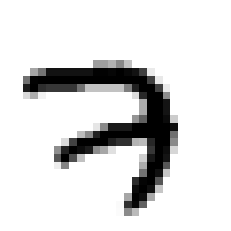

In [108]:
plt.imshow(X_train[0], cmap="binary")
plt.axis('off')
plt.show()

The labels are the class IDs (represented as uint8), from 0 to 9. Conveniently, the class IDs correspond to the digits represented in the images, so we don't need a `class_names` array:

In [109]:
y_train

array([7, 3, 4, ..., 5, 6, 8], dtype=uint8)

The validation set contains 5,000 images, and the test set contains 10,000 images:

In [110]:
X_valid.shape

(5000, 28, 28)

In [111]:
X_test.shape

(10000, 28, 28)

Let's take a look at a sample of the images in the dataset:

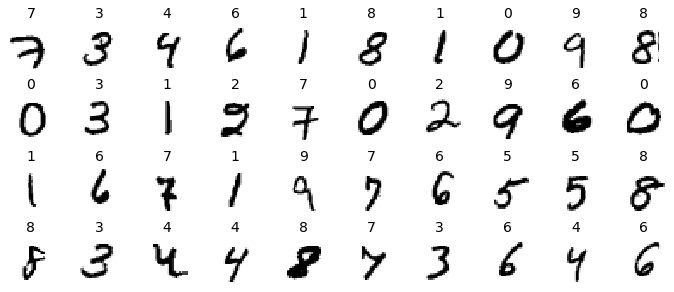

In [112]:
n_rows = 4
n_cols = 10
plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))
for row in range(n_rows):
    for col in range(n_cols):
        index = n_cols * row + col
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(X_train[index], cmap="binary", interpolation="nearest")
        plt.axis('off')
        plt.title(y_train[index])
plt.subplots_adjust(wspace=0.2, hspace=0.5)
plt.show()

Let's build a simple dense network and find the optimal learning rate. We will need a callback to grow the learning rate at each iteration. It will also record the learning rate and the loss at each iteration:

In [113]:
K = tf.keras.backend

class ExponentialLearningRate(tf.keras.callbacks.Callback):
    def __init__(self, factor):
        self.factor = factor
        self.rates = []
        self.losses = []
    def on_batch_end(self, batch, logs):
        self.rates.append(K.get_value(self.model.optimizer.learning_rate))
        self.losses.append(logs["loss"])
        K.set_value(self.model.optimizer.learning_rate, self.model.optimizer.learning_rate * self.factor)

In [114]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [115]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

We will start with a small learning rate of 1e-3, and grow it by 0.5% at each iteration:

In [116]:
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])
expon_lr = ExponentialLearningRate(factor=1.005)

Now let's train the model for just 1 epoch:

In [117]:
history = model.fit(X_train, y_train, epochs=1,
                    validation_data=(X_valid, y_valid),
                    callbacks=[expon_lr])

1719/1719 [==============================] - 2s 1ms/step - loss: 7045234294784.0000 - accuracy: 0.5774 - val_loss: 2.3911 - val_accuracy: 0.1126


We can now plot the loss as a functionof the learning rate:

Text(0, 0.5, 'Loss')

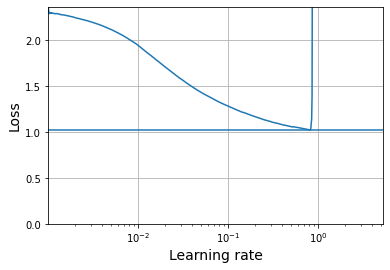

In [118]:
plt.plot(expon_lr.rates, expon_lr.losses)
plt.gca().set_xscale('log')
plt.hlines(min(expon_lr.losses), min(expon_lr.rates), max(expon_lr.rates))
plt.axis([min(expon_lr.rates), max(expon_lr.rates), 0, expon_lr.losses[0]])
plt.grid()
plt.xlabel("Learning rate")
plt.ylabel("Loss")

The loss starts shooting back up violently when the learning rate goes over 6e-1, so let's try using half of that, at 3e-1:

In [119]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [120]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [121]:
optimizer = tf.keras.optimizers.SGD(learning_rate=3e-1)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [122]:
run_index = 1 # increment this at every run
run_logdir = Path() / "my_mnist_logs" / "run_{:03d}".format(run_index)
run_logdir

PosixPath('my_mnist_logs/run_001')

In [123]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("my_mnist_model", save_best_only=True)
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)

history = model.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb, tensorboard_cb])

Epoch 1/100
1686/1719 [============================>.] - ETA: 0s - loss: 0.2336 - accuracy: 0.9268INFO:tensorflow:Assets written to: my_mnist_model/assets


INFO:tensorflow:Assets written to: my_mnist_model/assets


1719/1719 [==============================] - 2s 1ms/step - loss: 0.2319 - accuracy: 0.9274 - val_loss: 0.1102 - val_accuracy: 0.9698
Epoch 2/100
1688/1719 [============================>.] - ETA: 0s - loss: 0.0938 - accuracy: 0.9710INFO:tensorflow:Assets written to: my_mnist_model/assets


INFO:tensorflow:Assets written to: my_mnist_model/assets


1719/1719 [==============================] - 2s 1ms/step - loss: 0.0938 - accuracy: 0.9711 - val_loss: 0.0954 - val_accuracy: 0.9728
Epoch 3/100
1708/1719 [============================>.] - ETA: 0s - loss: 0.0665 - accuracy: 0.9791INFO:tensorflow:Assets written to: my_mnist_model/assets


INFO:tensorflow:Assets written to: my_mnist_model/assets


1719/1719 [==============================] - 2s 1ms/step - loss: 0.0664 - accuracy: 0.9791 - val_loss: 0.0678 - val_accuracy: 0.9788
Epoch 4/100
1719/1719 [==============================] - 2s 975us/step - loss: 0.0481 - accuracy: 0.9841 - val_loss: 0.0779 - val_accuracy: 0.9774
Epoch 5/100
1719/1719 [==============================] - 2s 959us/step - loss: 0.0352 - accuracy: 0.9882 - val_loss: 0.0872 - val_accuracy: 0.9776
Epoch 6/100
1717/1719 [============================>.] - ETA: 0s - loss: 0.0288 - accuracy: 0.9906INFO:tensorflow:Assets written to: my_mnist_model/assets


INFO:tensorflow:Assets written to: my_mnist_model/assets


1719/1719 [==============================] - 2s 1ms/step - loss: 0.0288 - accuracy: 0.9906 - val_loss: 0.0673 - val_accuracy: 0.9826
Epoch 7/100
1719/1719 [==============================] - 2s 981us/step - loss: 0.0205 - accuracy: 0.9933 - val_loss: 0.0728 - val_accuracy: 0.9824
Epoch 8/100
1719/1719 [==============================] - 2s 967us/step - loss: 0.0185 - accuracy: 0.9940 - val_loss: 0.0768 - val_accuracy: 0.9810
Epoch 9/100
1719/1719 [==============================] - 2s 970us/step - loss: 0.0160 - accuracy: 0.9947 - val_loss: 0.0821 - val_accuracy: 0.9808
Epoch 10/100
1719/1719 [==============================] - 2s 1ms/step - loss: 0.0115 - accuracy: 0.9961 - val_loss: 0.0915 - val_accuracy: 0.9810
Epoch 11/100
1719/1719 [==============================] - 2s 967us/step - loss: 0.0116 - accuracy: 0.9960 - val_loss: 0.0812 - val_accuracy: 0.9834
Epoch 12/100
1719/1719 [==============================] - 2s 961us/step - loss: 0.0097 - accuracy: 0.9965 - val_loss: 0.0816 - val_a

In [124]:
model = tf.keras.models.load_model("my_mnist_model") # rollback to best model
model.evaluate(X_test, y_test)

313/313 [==============================] - 0s 523us/step - loss: 0.0644 - accuracy: 0.9801


[0.0644259974360466, 0.9800999760627747]

We got over 98% accuracy. Finally, let's look at the learning curves using TensorBoard:

In [125]:
%tensorboard --logdir=./my_mnist_logs

ERROR: Failed to launch TensorBoard (exited with 1).
Contents of stderr:
W0526 14:16:04.123477 6147600384 plugin_event_accumulator.py:369] Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.
Address already in use
Port 6006 is in use by another program. Either identify and stop that program, or start the server with a different port.